In [12]:
print(results)

import numpy as np
imp = pd.Series(np.abs(sv).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print(imp.head(10).round(4))

                 Model  Recall  Precision  PR-AUC  ROC-AUC
0  Logistic Regression   0.712      0.166   0.275    0.883
1        Random Forest   0.182      0.632   0.414    0.943
2              XGBoost   0.500      0.465   0.457    0.949
Quick Ratio                                    0.8603
Total debt/Total net worth                     0.5867
Borrowing dependency                           0.5010
Continuous interest rate (after tax)           0.4298
Allocation rate per person                     0.4260
Persistent EPS in the Last Four Seasons        0.3882
Interest-bearing debt interest rate            0.3455
Non-industry income and expenditure/revenue    0.2877
Cash/Current Liability                         0.2506
Accounts Receivable Turnover                   0.2499
dtype: float32


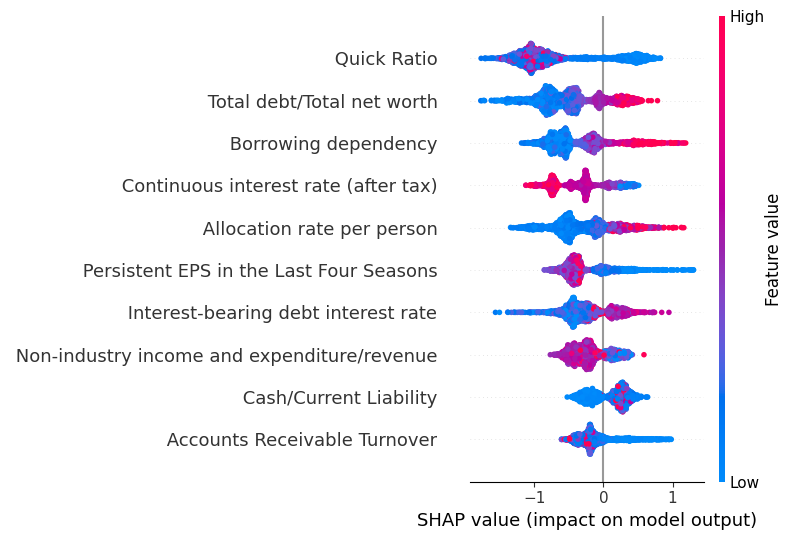

In [11]:
!pip install shap
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(X_test)

shap.summary_plot(sv, X_test, max_display=10, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
from sklearn.model_selection import cross_val_score

for name, m in [("Logistic Regression", logit), ("Random Forest", rf), ("XGBoost", xgb)]:
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="average_precision")
    print(name, "PR-AUC:", round(s.mean(), 3), "+/-", round(s.std(), 3))

Logistic Regression PR-AUC: 0.357 +/- 0.083
Random Forest PR-AUC: 0.382 +/- 0.05
XGBoost PR-AUC: 0.411 +/- 0.04


In [9]:
import pandas as pd

rows = []
for name, m in [("Logistic Regression", logit), ("Random Forest", rf), ("XGBoost", xgb)]:
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Recall": round(recall_score(y_test, pred), 3),
                 "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
                 "PR-AUC": round(average_precision_score(y_test, prob), 3),
                 "ROC-AUC": round(roc_auc_score(y_test, prob), 3)})

results = pd.DataFrame(rows)
print(results)
results.to_csv("model_results.csv", index=False)

                 Model  Recall  Precision  PR-AUC  ROC-AUC
0  Logistic Regression   0.712      0.166   0.275    0.883
1        Random Forest   0.182      0.632   0.414    0.943
2              XGBoost   0.500      0.465   0.457    0.949


In [8]:
from xgboost import XGBClassifier

spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    scale_pos_weight=spw, eval_metric="aucpr",
                    random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
report("XGBoost", xgb)

XGBoost
Recall   : 0.5
Precision: 0.465
PR-AUC   : 0.457
ROC-AUC  : 0.949


In [7]:
prob = rf.predict_proba(X_test)[:, 1]
pred = (prob >= best).astype(int)
print("Recall   :", round(recall_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
print("F1       :", round(f1_score(y_test, pred), 3))

Recall   : 0.576
Precision: 0.373
F1       : 0.452


In [6]:
import numpy as np
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

p, r, t = precision_recall_curve(y_train, oof)
f1 = 2*p*r/(p+r+1e-9)
best = t[np.argmax(f1[:-1])]
print("Chosen threshold:", round(best, 3))

Chosen threshold: 0.163


In [5]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
report("Random Forest", rf)

Random Forest
Recall   : 0.182
Precision: 0.632
PR-AUC   : 0.414
ROC-AUC  : 0.943


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, average_precision_score, roc_auc_score

def report(name, model):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    print(name)
    print("Recall   :", round(recall_score(y_test, pred), 3))
    print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
    print("PR-AUC   :", round(average_precision_score(y_test, prob), 3))
    print("ROC-AUC  :", round(roc_auc_score(y_test, prob), 3))

logit = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=2000, class_weight="balanced"))
logit.fit(X_train, y_train)
report("Logistic Regression", logit)

Logistic Regression
Recall   : 0.712
Precision: 0.166
PR-AUC   : 0.275
ROC-AUC  : 0.883


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print("Bankrupt in train:", y_train.sum(), "| in test:", y_test.sum())

(4773, 95) (2046, 95)
Bankrupt in train: 154 | in test: 66


In [2]:
y = y.squeeze()
print(X.shape)
print(y.value_counts())
print(round(y.mean()*100, 2), "% bankrupt")
print("Missing values:", X.isna().sum().sum())

(6819, 95)
Bankrupt?
0    6599
1     220
Name: count, dtype: int64
3.23 % bankrupt
Missing values: 0


In [1]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
d = fetch_ucirepo(id=572)
X = d.data.features
y = d.data.targets
print(X.shape, y.value_counts())

(6819, 95) Bankrupt?
0            6599
1             220
Name: count, dtype: int64
